In [1]:
# ==============================
# DATA HANDLING
# ==============================
import pandas as pd
import numpy as np

# ==============================
# DATA VISUALIZATION
# ==============================
import matplotlib.pyplot as plt
import seaborn as sns

# ==============================
# NLP - TEXT PREPROCESSING
# ==============================
import re
import string
import nltk

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize

# ==============================
# MACHINE LEARNING
# ==============================
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Logistic Regression
from sklearn.linear_model import LogisticRegression

# Support Vector Machine
from sklearn.svm import LinearSVC

# ==============================
# MODEL EVALUATION
# ==============================
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
# ==============================
# ROC CURVE & AUC
# ==============================
from sklearn.metrics import roc_curve, auc, roc_auc_score
from sklearn.preprocessing import label_binarize

# ==============================
# MODEL SAVING
# ==============================
import joblib

# ==============================
# WARNINGS
# ==============================
import warnings
warnings.filterwarnings("ignore")

print("All required libraries imported successfully!")

All required libraries imported successfully!


In [3]:
#Dataset Loading
df = pd.read_excel("/content/Aditya_University_Sentiment_Final_Dataset.xlsx")
print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


In [ ]:
#Display First five records
df.head()

,Comment_ID,Platform,Comment,Sentiment,Aspect,Rating,Student_Type,Year_of_Study,Comment_Length,Engagement_Score
0,102,YouTube,Canteen service the process is familiar to mos...,negative,Campus,3.0,PG Student,1st Year,26,19.0
1,755,Shiksha,Library service students have different views ...,positive,Transport,4.0,UG Student,2nd Year,28,40.0
2,309,YouTube,Laboratory facilities some days are easier tha...,positive,Placement,5.0,Applicant,1st Year,22,31.0
3,110,YouTube,Classrooms the process is familiar to most stu...,positive,Faculty,5.0,Applicant,Alumni,24,92.0
4,651,YouTube,Career guidance students use it as part of the...,negative,Placement,4.0,Parent,Postgraduate,28,82.0


In [4]:
# Dataset Shape
df.shape
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 1208
Number of columns: 10


In [5]:
#check Column Names
df.columns

Index(['Comment_ID', 'Platform', 'Comment', 'Sentiment', 'Aspect', 'Rating',
       'Student_Type', 'Year_of_Study', 'Comment_Length', 'Engagement_Score'],
      dtype='object')

In [6]:
#check datatypes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1208 entries, 0 to 1207
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Comment_ID        1208 non-null   int64  
 1   Platform          1205 non-null   object 
 2   Comment           1208 non-null   object 
 3   Sentiment         1208 non-null   object 
 4   Aspect            1205 non-null   object 
 5   Rating            1205 non-null   float64
 6   Student_Type      1206 non-null   object 
 7   Year_of_Study     1206 non-null   object 
 8   Comment_Length    1208 non-null   int64  
 9   Engagement_Score  1205 non-null   float64
dtypes: float64(2), int64(2), object(6)
memory usage: 94.5+ KB


In [7]:
df.describe()

,Comment_ID,Rating,Comment_Length,Engagement_Score
count,1208.000000,1205.000000,1208.000000,1205.000000
mean,599.615066,3.521162,25.308775,53.333610
std,346.788074,1.120153,2.493044,24.519263
min,1.000000,2.000000,16.000000,10.000000
25%,299.750000,3.000000,24.000000,33.000000
50%,599.500000,4.000000,25.000000,53.000000
75%,899.250000,5.000000,27.000000,74.000000
max,1200.000000,5.000000,33.000000,95.000000


In [8]:
#checking missing values
df.isnull().sum()

,0
Comment_ID,0
Platform,3
Comment,0
Sentiment,0
Aspect,3
Rating,3
Student_Type,2
Year_of_Study,2
Comment_Length,0
Engagement_Score,3


In [9]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 16


In [10]:
#Check duplicate records
df.duplicated().sum()

np.int64(8)

In [11]:
#Check sentiment distribution
df["Sentiment"].value_counts(dropna=False)

,count
Sentiment,
negative,447
neutral,393
positive,368


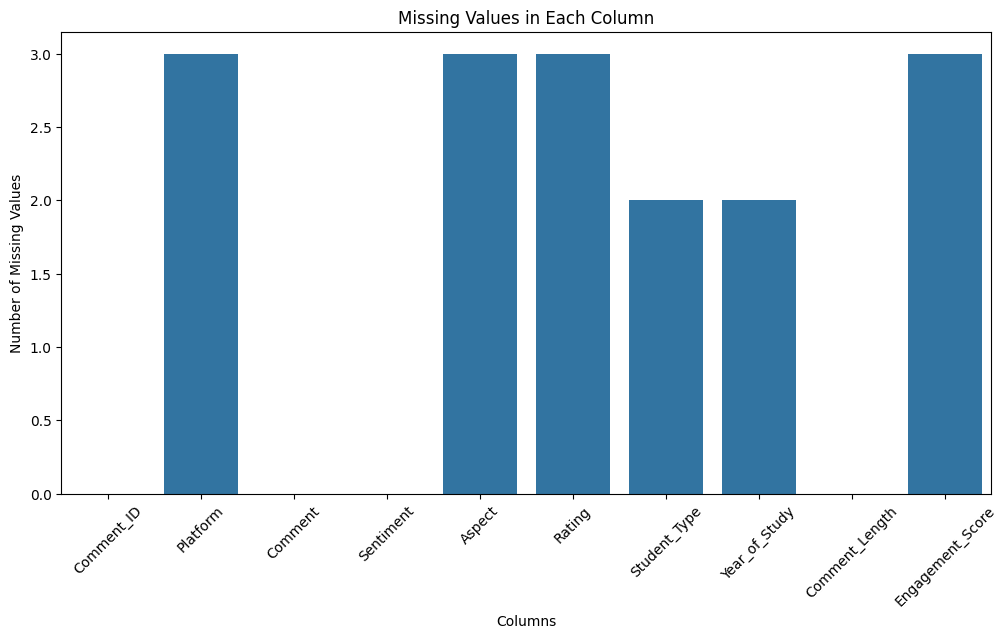

In [12]:
#Missing Values Graph
plt.figure(figsize=(12,6))

sns.barplot(
    x=df.columns,
    y=df.isnull().sum()
)

plt.title("Missing Values in Each Column")
plt.xlabel("Columns")
plt.ylabel("Number of Missing Values")

plt.xticks(rotation=45)

plt.show()

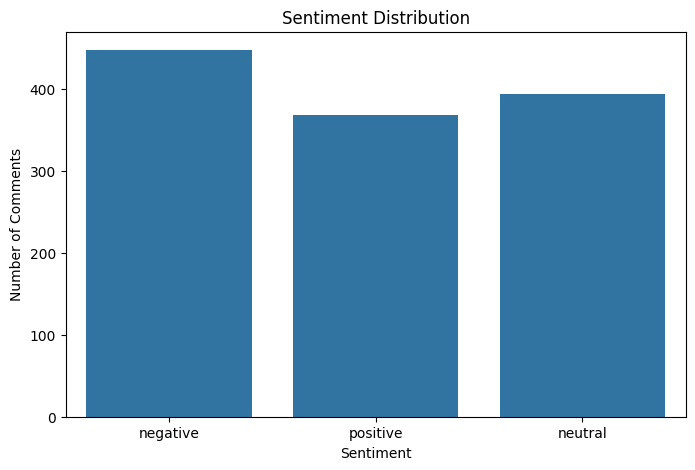

In [13]:
# senti distribution Graph
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Sentiment"
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Comments")

plt.show()

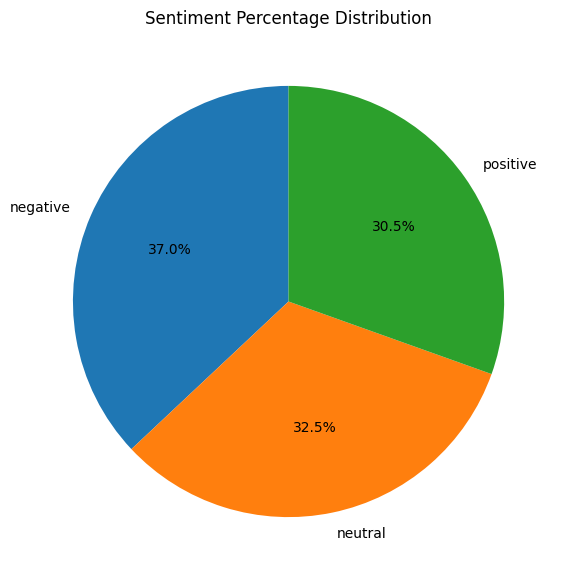

In [14]:
sentiment_counts = df["Sentiment"].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    sentiment_counts,
    labels=sentiment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Sentiment Percentage Distribution")

plt.show()

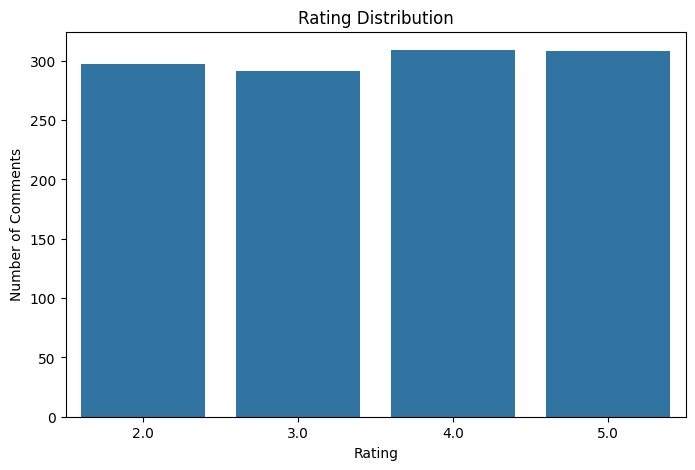

In [15]:
#Rating Distribution
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="Rating"
)

plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Comments")

plt.show()

In [16]:
#Step : 2
#Data Cleaning
#Check the dataset again
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

Dataset Shape: (1208, 10)

Column Names:
['Comment_ID', 'Platform', 'Comment', 'Sentiment', 'Aspect', 'Rating', 'Student_Type', 'Year_of_Study', 'Comment_Length', 'Engagement_Score']

Data Types:
Comment_ID            int64
Platform             object
Comment              object
Sentiment            object
Aspect               object
Rating              float64
Student_Type         object
Year_of_Study        object
Comment_Length        int64
Engagement_Score    float64
dtype: object


In [17]:
#checking missing values
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
Comment_ID          0
Platform            3
Comment             0
Sentiment           0
Aspect              3
Rating              3
Student_Type        2
Year_of_Study       2
Comment_Length      0
Engagement_Score    3
dtype: int64


In [18]:
# Duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 8


In [19]:
# Correct categorical columns
categorical_columns = [
    "Platform",
    "Sentiment",
    "Aspect",
    "Student_Type",
    "Year_of_Study"
]

for col in categorical_columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

# Correct numerical columns
numerical_columns = [
    "Rating",
    "Comment_Length",
    "Engagement_Score"
]

for col in numerical_columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

print("Missing values filled successfully!")


Missing values filled successfully!


In [20]:
# STEP 2.4 — Remove Duplicate Rows

before = len(df)

df = df.drop_duplicates()

after = len(df)

print("Rows before removing duplicates:", before)
print("Rows after removing duplicates :", after)
print("Duplicates removed             :", before - after)

Rows before removing duplicates: 1208
Rows after removing duplicates : 1200
Duplicates removed             : 8


In [21]:
# Drop rows where Comment or Sentiment is missing
df = df.dropna(subset=["Comment", "Sentiment"]).reset_index(drop=True)

print("Shape after removing missing Comment/Sentiment:")
print(df.shape)


Shape after removing missing Comment/Sentiment:
(1200, 10)


In [22]:
#Check sentiment values
print(df["Sentiment"].value_counts())
print(df["Sentiment"].unique())

Sentiment
negative    444
neutral     389
positive    367
Name: count, dtype: int64
['negative' 'positive' 'neutral']


In [23]:
#Standardize sentiment labels
df["Sentiment"] = df["Sentiment"].astype(str).str.strip().str.lower()

print(df["Sentiment"].value_counts())

Sentiment
negative    444
neutral     389
positive    367
Name: count, dtype: int64


In [24]:
# Drop rows where Comment or Sentiment is missing
df = df.dropna(subset=["Comment", "Sentiment"]).reset_index(drop=True)

print("Shape after removing missing Comment/Sentiment:")
print(df.shape)


Shape after removing missing Comment/Sentiment:
(1200, 10)


In [25]:
# Check duplicate comments before removing them

print("Total rows:", len(df))
print("Duplicate comments:", df["Comment"].duplicated().sum())

Total rows: 1200
Duplicate comments: 0


In [26]:
# Remove duplicate comments
df = df.drop_duplicates(
    subset=["Comment"],   # ✅ use Comment instead of Review
    keep="first"
).reset_index(drop=True)

print("Rows after removing duplicate comments:", len(df))
print("Duplicate comments remaining:", df["Comment"].duplicated().sum())


Rows after removing duplicate comments: 1200
Duplicate comments remaining: 0


In [27]:
df.head()

,Comment_ID,Platform,Comment,Sentiment,Aspect,Rating,Student_Type,Year_of_Study,Comment_Length,Engagement_Score
0,102,YouTube,Canteen service the process is familiar to mos...,negative,Campus,3.0,PG Student,1st Year,26,19.0
1,755,Shiksha,Library service students have different views ...,positive,Transport,4.0,UG Student,2nd Year,28,40.0
2,309,YouTube,Laboratory facilities some days are easier tha...,positive,Placement,5.0,Applicant,1st Year,22,31.0
3,110,YouTube,Classrooms the process is familiar to most stu...,positive,Faculty,5.0,Applicant,Alumni,24,92.0
4,651,YouTube,Career guidance students use it as part of the...,negative,Placement,4.0,Parent,Postgraduate,28,82.0


In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 10 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Comment_ID        1200 non-null   int64  
 1   Platform          1200 non-null   object 
 2   Comment           1200 non-null   object 
 3   Sentiment         1200 non-null   object 
 4   Aspect            1200 non-null   object 
 5   Rating            1200 non-null   float64
 6   Student_Type      1200 non-null   object 
 7   Year_of_Study     1200 non-null   object 
 8   Comment_Length    1200 non-null   int64  
 9   Engagement_Score  1200 non-null   float64
dtypes: float64(2), int64(2), object(6)
memory usage: 93.9+ KB


In [29]:
# STEP 2.5 — Verify Cleaning

print("Missing values after cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows after cleaning:")
print(df.duplicated().sum())

Missing values after cleaning:
Comment_ID          0
Platform            0
Comment             0
Sentiment           0
Aspect              0
Rating              0
Student_Type        0
Year_of_Study       0
Comment_Length      0
Engagement_Score    0
dtype: int64

Duplicate rows after cleaning:
0


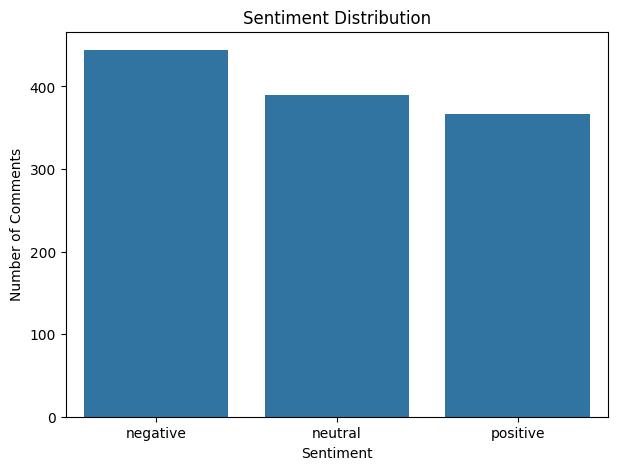

In [30]:
#Visualize sentiment distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Sentiment",
    order=df["Sentiment"].value_counts().index
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Comments")
plt.show()

In [33]:
df.to_csv(
    (r"/content/Aditya_University_Sentiment_Final_Datasettt.xlsx"),
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


EXPLORATORY DATA ANALYSIS

1. DATASET SHAPE
----------------------------------------
Rows    : 1200
Columns : 10

Column Names:
['Comment_ID', 'Platform', 'Comment', 'Sentiment', 'Aspect', 'Rating', 'Student_Type', 'Year_of_Study', 'Comment_Length', 'Engagement_Score']

2. STATISTICAL SUMMARY
----------------------------------------


,Comment_ID,Rating,Comment_Length,Engagement_Score
count,1200.000000,1200.000000,1200.000000,1200.000000
mean,600.500000,3.523333,25.315000,53.368333
std,346.554469,1.119747,2.496525,24.502986
min,1.000000,2.000000,16.000000,10.000000
25%,300.750000,3.000000,24.000000,33.000000
50%,600.500000,4.000000,25.000000,53.000000
75%,900.250000,5.000000,27.000000,74.000000
max,1200.000000,5.000000,33.000000,95.000000



3. SENTIMENT DISTRIBUTION
----------------------------------------
Sentiment
negative    444
neutral     389
positive    367
Name: count, dtype: int64


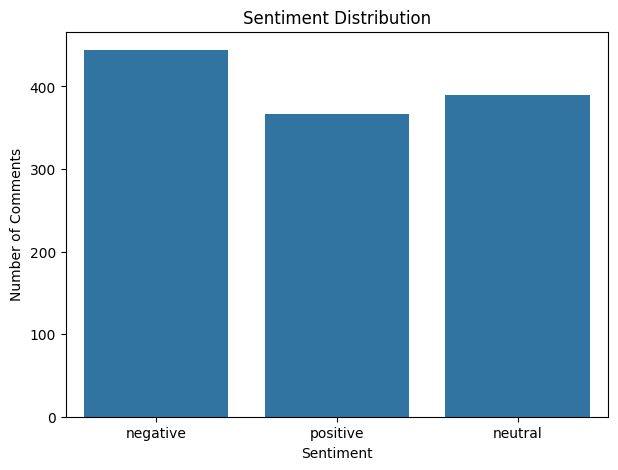


4. PLATFORM DISTRIBUTION
----------------------------------------
Platform
YouTube         273
LinkedIn        239
Careers360      232
CollegeDunia    229
Shiksha         227
Name: count, dtype: int64


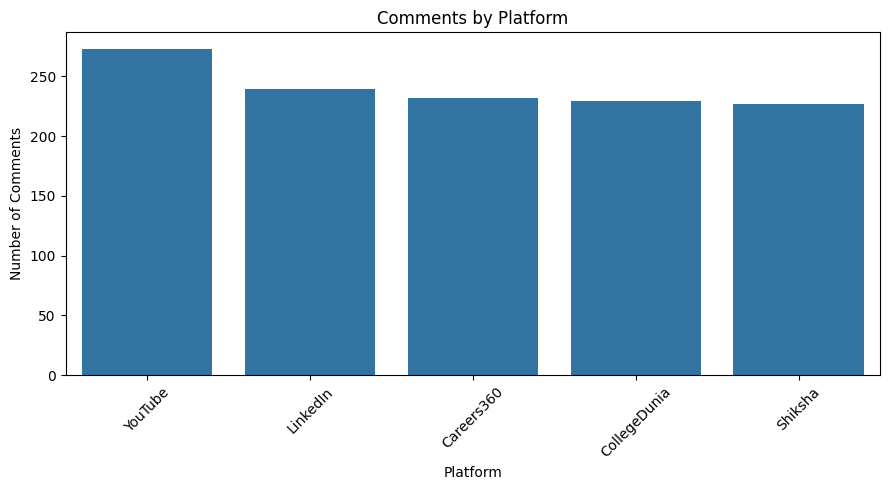


5. ASPECT DISTRIBUTION
----------------------------------------
Aspect
Campus        171
Placement     161
Hostel        159
Transport     153
Facilities    147
Library       141
Faculty       135
Activities    133
Name: count, dtype: int64


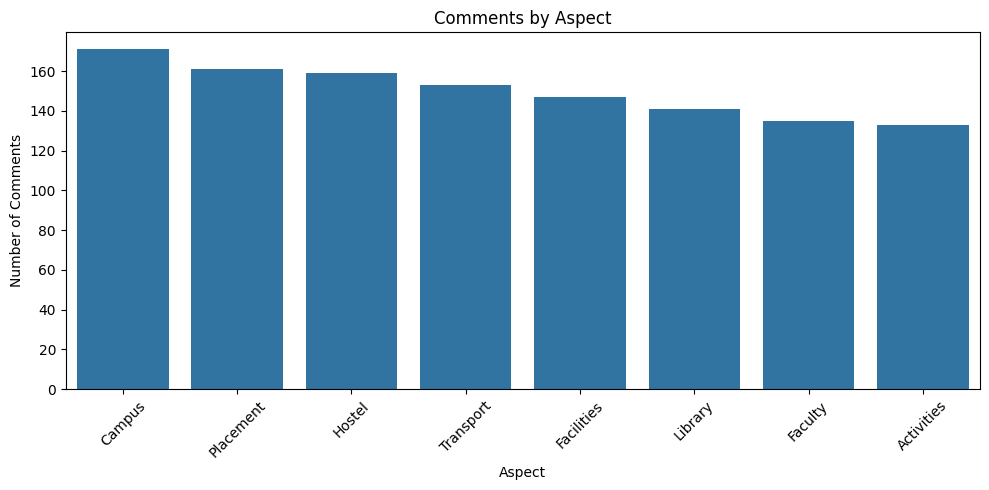

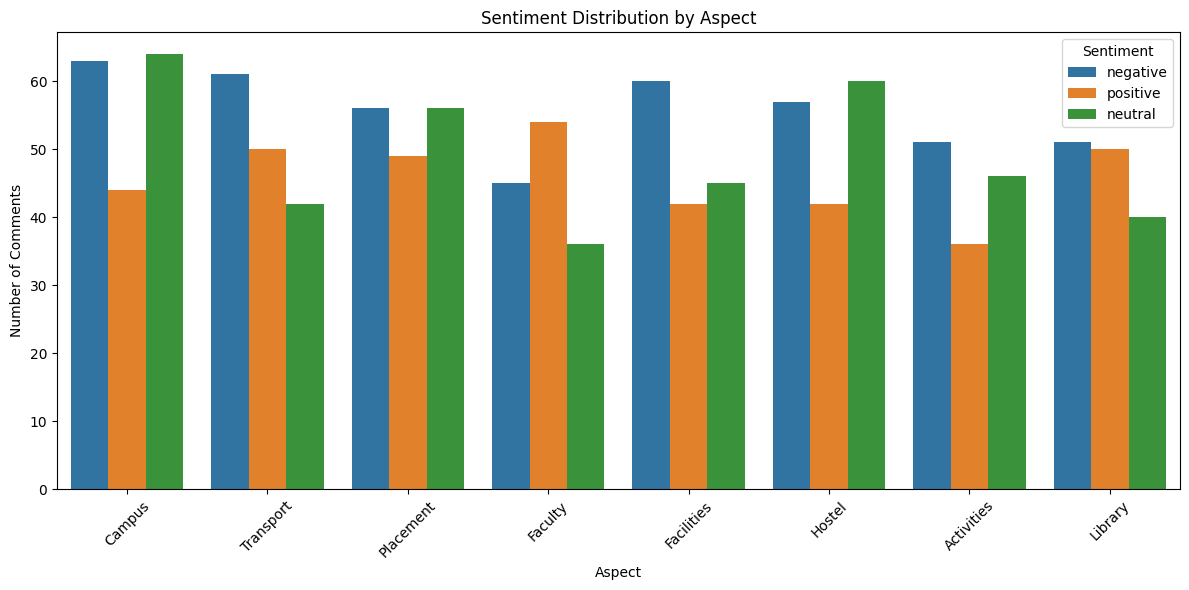


7. RATING DISTRIBUTION
----------------------------------------
Rating
2.0    295
3.0    289
4.0    309
5.0    307
Name: count, dtype: int64


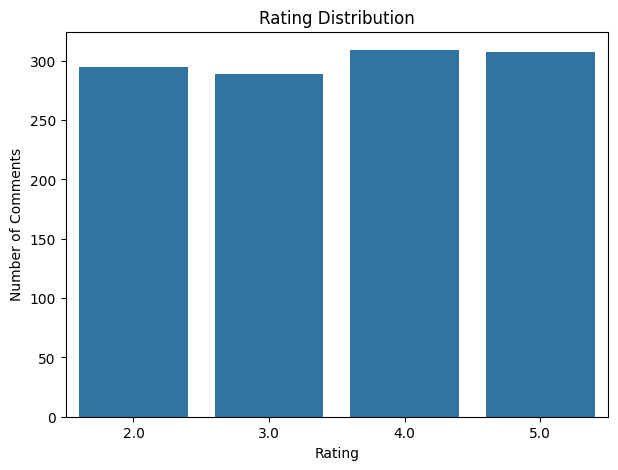

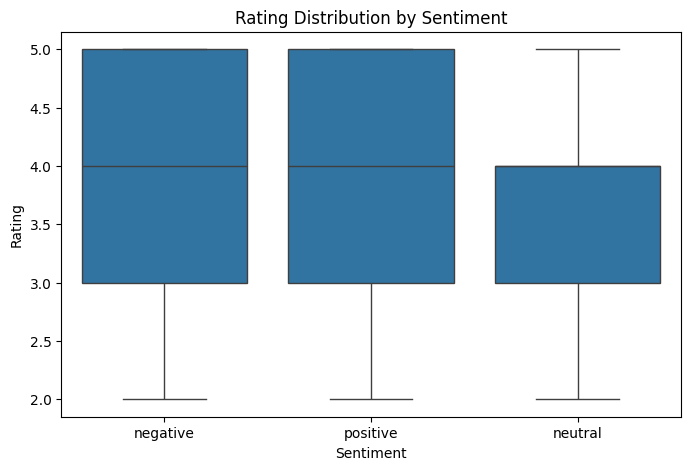

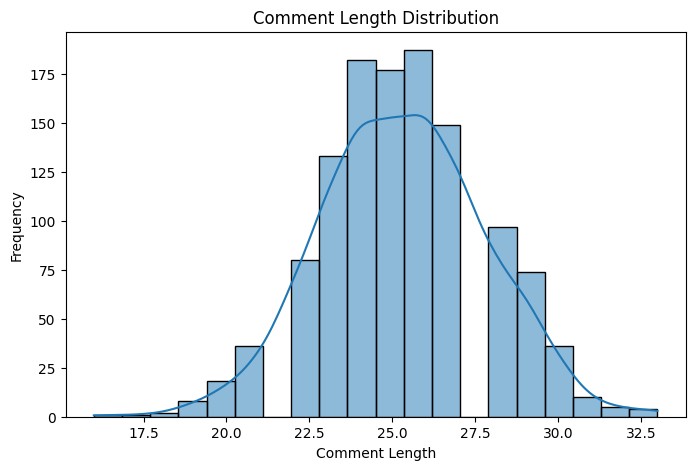

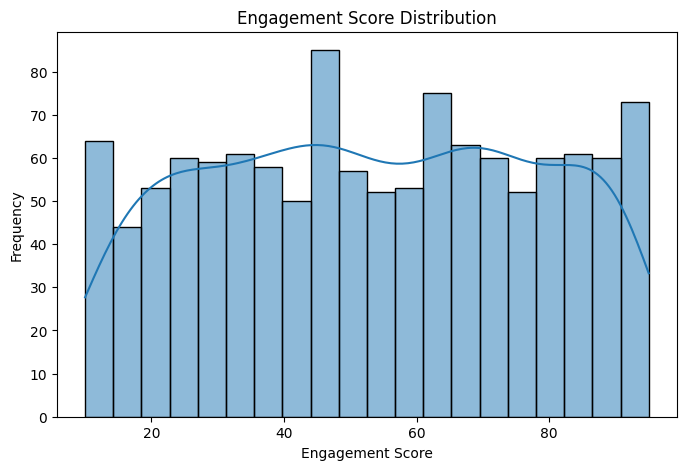

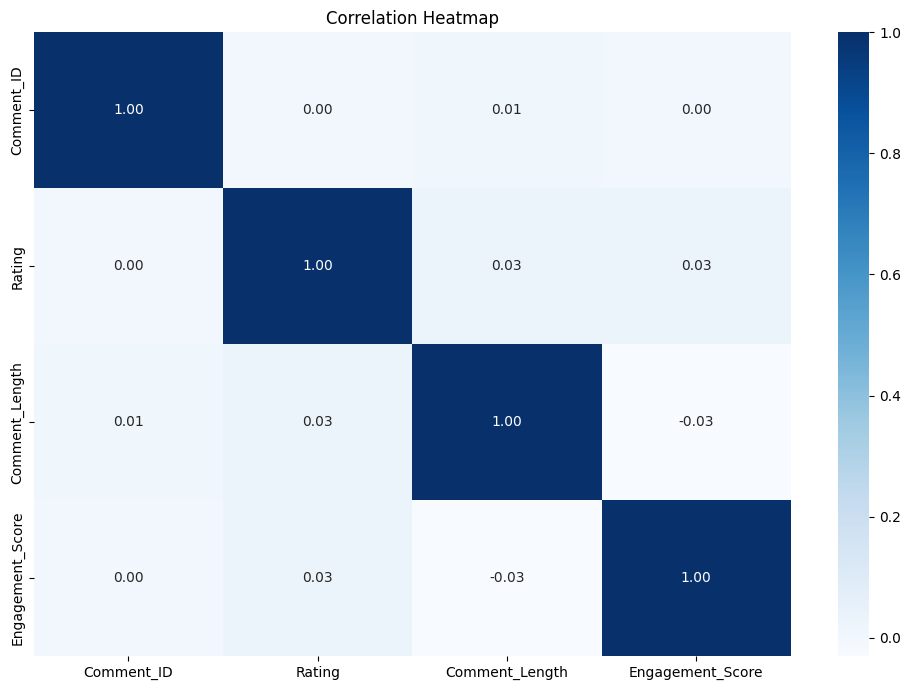

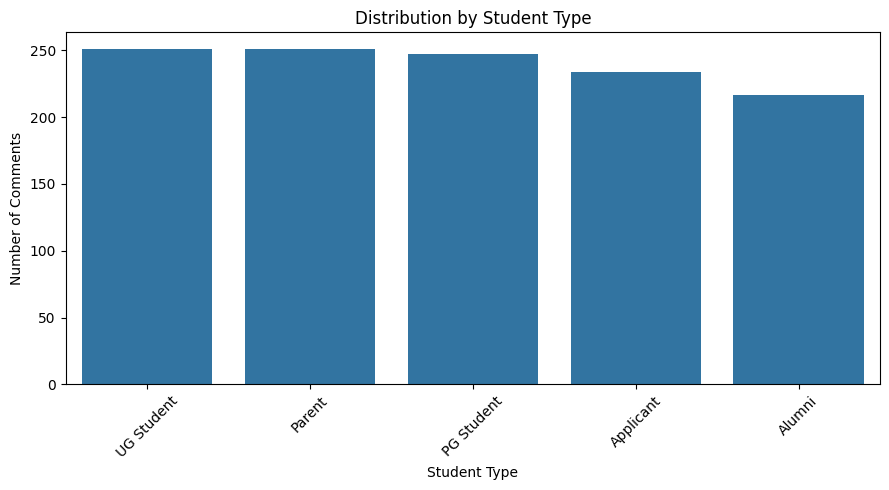

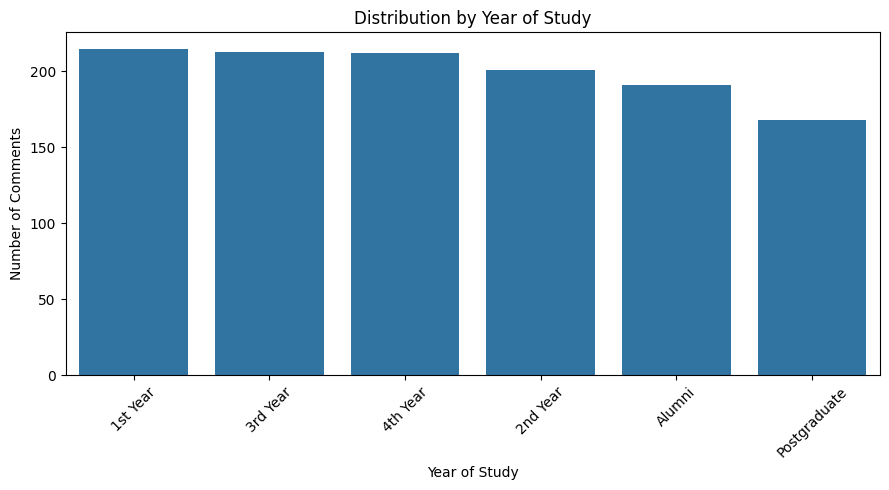


EDA COMPLETED SUCCESSFULLY!


In [34]:
# ============================================================
# STEP 3 — EXPLORATORY DATA ANALYSIS (EDA)
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

print("=" * 60)
print("EXPLORATORY DATA ANALYSIS")
print("=" * 60)

# ------------------------------------------------------------
# 1. Dataset Information
# ------------------------------------------------------------
print("\n1. DATASET SHAPE")
print("-" * 40)
print("Rows    :", df.shape[0])
print("Columns :", df.shape[1])

print("\nColumn Names:")
print(df.columns.tolist())


# ------------------------------------------------------------
# 2. Statistical Summary
# ------------------------------------------------------------
print("\n2. STATISTICAL SUMMARY")
print("-" * 40)
display(df.describe())


# ------------------------------------------------------------
# 3. Sentiment Distribution
# ------------------------------------------------------------
print("\n3. SENTIMENT DISTRIBUTION")
print("-" * 40)
print(df["Sentiment"].value_counts())

plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Sentiment")
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Comments")
plt.show()


# ------------------------------------------------------------
# 4. Platform Distribution
# ------------------------------------------------------------
print("\n4. PLATFORM DISTRIBUTION")
print("-" * 40)
print(df["Platform"].value_counts())

plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x="Platform",
    order=df["Platform"].value_counts().index
)
plt.title("Comments by Platform")
plt.xlabel("Platform")
plt.ylabel("Number of Comments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. Aspect Distribution
# ------------------------------------------------------------
print("\n5. ASPECT DISTRIBUTION")
print("-" * 40)
print(df["Aspect"].value_counts())

plt.figure(figsize=(10, 5))
sns.countplot(
    data=df,
    x="Aspect",
    order=df["Aspect"].value_counts().index
)
plt.title("Comments by Aspect")
plt.xlabel("Aspect")
plt.ylabel("Number of Comments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 6. Sentiment by Aspect
# ------------------------------------------------------------
plt.figure(figsize=(12, 6))
sns.countplot(
    data=df,
    x="Aspect",
    hue="Sentiment"
)
plt.title("Sentiment Distribution by Aspect")
plt.xlabel("Aspect")
plt.ylabel("Number of Comments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 7. Rating Distribution
# ------------------------------------------------------------
print("\n7. RATING DISTRIBUTION")
print("-" * 40)
print(df["Rating"].value_counts().sort_index())

plt.figure(figsize=(7, 5))
sns.countplot(
    data=df,
    x="Rating",
    order=sorted(df["Rating"].unique())
)
plt.title("Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Comments")
plt.show()


# ------------------------------------------------------------
# 8. Rating vs Sentiment
# ------------------------------------------------------------
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x="Sentiment",
    y="Rating"
)
plt.title("Rating Distribution by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Rating")
plt.show()


# ------------------------------------------------------------
# 9. Comment Length Distribution
# ------------------------------------------------------------
plt.figure(figsize=(8, 5))
sns.histplot(
    data=df,
    x="Comment_Length",
    bins=20,
    kde=True
)
plt.title("Comment Length Distribution")
plt.xlabel("Comment Length")
plt.ylabel("Frequency")
plt.show()


# ------------------------------------------------------------
# 10. Engagement Score Distribution
# ------------------------------------------------------------
plt.figure(figsize=(8, 5))
sns.histplot(
    data=df,
    x="Engagement_Score",
    bins=20,
    kde=True
)
plt.title("Engagement Score Distribution")
plt.xlabel("Engagement Score")
plt.ylabel("Frequency")
plt.show()


# ------------------------------------------------------------
# 11. Correlation Heatmap
# ------------------------------------------------------------
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(10, 7))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    fmt=".2f",
    cmap="Blues"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12. Student Type Distribution
# ------------------------------------------------------------
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x="Student_Type",
    order=df["Student_Type"].value_counts().index
)
plt.title("Distribution by Student Type")
plt.xlabel("Student Type")
plt.ylabel("Number of Comments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 13. Year of Study Distribution
# ------------------------------------------------------------
plt.figure(figsize=(9, 5))
sns.countplot(
    data=df,
    x="Year_of_Study",
    order=df["Year_of_Study"].value_counts().index
)
plt.title("Distribution by Year of Study")
plt.xlabel("Year of Study")
plt.ylabel("Number of Comments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


print("\n" + "=" * 60)
print("EDA COMPLETED SUCCESSFULLY!")
print("=" * 60)


In [35]:
# STEP 4.1 — NLP Resources

import nltk

nltk.download("stopwords")
nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [36]:
df[["Comment"]].head(10)


,Comment
0,Canteen service the process is familiar to mos...
1,Library service students have different views ...
2,Laboratory facilities some days are easier tha...
3,Classrooms the process is familiar to most stu...
4,Career guidance students use it as part of the...
5,Classrooms the arrangements are usually manage...
6,Administrative support students use it as part...
7,Academic schedule the arrangements are usually...
8,Faculty support the facility is available duri...
9,Laboratory facilities the arrangement has rema...


In [37]:
#Convert text to lowercase
df["Lowercase_Comment"] = df["Comment"].astype(str).str.lower()

df[["Comment", "Lowercase_Comment"]].head(10)

,Comment,Lowercase_Comment
0,Canteen service the process is familiar to mos...,canteen service the process is familiar to mos...
1,Library service students have different views ...,library service students have different views ...
2,Laboratory facilities some days are easier tha...,laboratory facilities some days are easier tha...
3,Classrooms the process is familiar to most stu...,classrooms the process is familiar to most stu...
4,Career guidance students use it as part of the...,career guidance students use it as part of the...
5,Classrooms the arrangements are usually manage...,classrooms the arrangements are usually manage...
6,Administrative support students use it as part...,administrative support students use it as part...
7,Academic schedule the arrangements are usually...,academic schedule the arrangements are usually...
8,Faculty support the facility is available duri...,faculty support the facility is available duri...
9,Laboratory facilities the arrangement has rema...,laboratory facilities the arrangement has rema...


In [38]:
#Remove urls
def remove_urls(text):
    return re.sub(r"http\S+|www\S+|https\S+", "", text)

df["No_URL_Comment"] = df["Lowercase_Comment"].apply(remove_urls)

df[["Lowercase_Comment", "No_URL_Comment"]].head(10)

,Lowercase_Comment,No_URL_Comment
0,canteen service the process is familiar to mos...,canteen service the process is familiar to mos...
1,library service students have different views ...,library service students have different views ...
2,laboratory facilities some days are easier tha...,laboratory facilities some days are easier tha...
3,classrooms the process is familiar to most stu...,classrooms the process is familiar to most stu...
4,career guidance students use it as part of the...,career guidance students use it as part of the...
5,classrooms the arrangements are usually manage...,classrooms the arrangements are usually manage...
6,administrative support students use it as part...,administrative support students use it as part...
7,academic schedule the arrangements are usually...,academic schedule the arrangements are usually...
8,faculty support the facility is available duri...,faculty support the facility is available duri...
9,laboratory facilities the arrangement has rema...,laboratory facilities the arrangement has rema...


In [39]:
#Remove punctuation
def remove_punctuation(text):
    return text.translate(
        str.maketrans("", "", string.punctuation)
    )

df["No_Punctuation_Comment"] = df["No_URL_Comment"].apply(
    remove_punctuation
)

df[["No_URL_Comment", "No_Punctuation_Comment"]].head(10)

,No_URL_Comment,No_Punctuation_Comment
0,canteen service the process is familiar to mos...,canteen service the process is familiar to mos...
1,library service students have different views ...,library service students have different views ...
2,laboratory facilities some days are easier tha...,laboratory facilities some days are easier tha...
3,classrooms the process is familiar to most stu...,classrooms the process is familiar to most stu...
4,career guidance students use it as part of the...,career guidance students use it as part of the...
5,classrooms the arrangements are usually manage...,classrooms the arrangements are usually manage...
6,administrative support students use it as part...,administrative support students use it as part...
7,academic schedule the arrangements are usually...,academic schedule the arrangements are usually...
8,faculty support the facility is available duri...,faculty support the facility is available duri...
9,laboratory facilities the arrangement has rema...,laboratory facilities the arrangement has rema...


In [40]:
print(df.columns.tolist())

['Comment_ID', 'Platform', 'Comment', 'Sentiment', 'Aspect', 'Rating', 'Student_Type', 'Year_of_Study', 'Comment_Length', 'Engagement_Score', 'Lowercase_Comment', 'No_URL_Comment', 'No_Punctuation_Comment']


In [41]:
# Remove numbers from Comment
df["No_Numbers_Comment"] = (
    df["Comment"]
    .str.replace(r"\d+", "", regex=True)
)

# Remove extra spaces
df["No_Numbers_Comment"] = (
    df["No_Numbers_Comment"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

print(df[["Comment", "No_Numbers_Comment"]].head())

                                             Comment  \
0  Canteen service the process is familiar to mos...   
1  Library service students have different views ...   
2  Laboratory facilities some days are easier tha...   
3  Classrooms the process is familiar to most stu...   
4  Career guidance students use it as part of the...   

                                  No_Numbers_Comment  
0  Canteen service the process is familiar to mos...  
1  Library service students have different views ...  
2  Laboratory facilities some days are easier tha...  
3  Classrooms the process is familiar to most stu...  
4  Career guidance students use it as part of the...  


In [42]:
#Tokenization
from nltk.tokenize import word_tokenize

df["Tokens"] = df["No_Numbers_Comment"].apply(
    word_tokenize
)

df[["No_Numbers_Comment", "Tokens"]].head(10)

,No_Numbers_Comment,Tokens
0,Canteen service the process is familiar to mos...,"[Canteen, service, the, process, is, familiar,..."
1,Library service students have different views ...,"[Library, service, students, have, different, ..."
2,Laboratory facilities some days are easier tha...,"[Laboratory, facilities, some, days, are, easi..."
3,Classrooms the process is familiar to most stu...,"[Classrooms, the, process, is, familiar, to, m..."
4,Career guidance students use it as part of the...,"[Career, guidance, students, use, it, as, part..."
5,Classrooms the arrangements are usually manage...,"[Classrooms, the, arrangements, are, usually, ..."
6,Administrative support students use it as part...,"[Administrative, support, students, use, it, a..."
7,Academic schedule the arrangements are usually...,"[Academic, schedule, the, arrangements, are, u..."
8,Faculty support the facility is available duri...,"[Faculty, support, the, facility, is, availabl..."
9,Laboratory facilities the arrangement has rema...,"[Laboratory, facilities, the, arrangement, has..."


In [43]:
#Stop word Removal
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

df["Filtered_Tokens"] = df["Tokens"].apply(
    lambda tokens: [
        word for word in tokens
        if word not in stop_words
    ]
)

df[["Tokens", "Filtered_Tokens"]].head(10)

,Tokens,Filtered_Tokens
0,"[Canteen, service, the, process, is, familiar,...","[Canteen, service, process, familiar, students..."
1,"[Library, service, students, have, different, ...","[Library, service, students, different, views,..."
2,"[Laboratory, facilities, some, days, are, easi...","[Laboratory, facilities, days, easier, others,..."
3,"[Classrooms, the, process, is, familiar, to, m...","[Classrooms, process, familiar, students, ,, p..."
4,"[Career, guidance, students, use, it, as, part...","[Career, guidance, students, use, part, routin..."
5,"[Classrooms, the, arrangements, are, usually, ...","[Classrooms, arrangements, usually, manageable..."
6,"[Administrative, support, students, use, it, a...","[Administrative, support, students, use, part,..."
7,"[Academic, schedule, the, arrangements, are, u...","[Academic, schedule, arrangements, usually, ma..."
8,"[Faculty, support, the, facility, is, availabl...","[Faculty, support, facility, available, semest..."
9,"[Laboratory, facilities, the, arrangement, has...","[Laboratory, facilities, arrangement, remained..."


In [44]:
import nltk
from nltk.stem import WordNetLemmatizer

# Download WordNet if not already present
nltk.download('wordnet')
nltk.download('omw-1.4')

lemmatizer = WordNetLemmatizer()

df["Lemmatized_Tokens"] = df["Filtered_Tokens"].apply(
    lambda tokens: [lemmatizer.lemmatize(word) for word in tokens]
)

print(df[["Filtered_Tokens", "Lemmatized_Tokens"]].head(10))


[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


                                     Filtered_Tokens  \
0  [Canteen, service, process, familiar, students...   
1  [Library, service, students, different, views,...   
2  [Laboratory, facilities, days, easier, others,...   
3  [Classrooms, process, familiar, students, ,, p...   
4  [Career, guidance, students, use, part, routin...   
5  [Classrooms, arrangements, usually, manageable...   
6  [Administrative, support, students, use, part,...   
7  [Academic, schedule, arrangements, usually, ma...   
8  [Faculty, support, facility, available, semest...   
9  [Laboratory, facilities, arrangement, remained...   

                                   Lemmatized_Tokens  
0  [Canteen, service, process, familiar, student,...  
1  [Library, service, student, different, view, s...  
2  [Laboratory, facility, day, easier, others, ,,...  
3  [Classrooms, process, familiar, student, ,, pr...  
4  [Career, guidance, student, use, part, routine...  
5  [Classrooms, arrangement, usually, manageable,... 

In [45]:
#final cleaned text
df["Cleaned_Comment"] = df["Lemmatized_Tokens"].apply(
    lambda tokens: " ".join(tokens)
)

df[["Comment", "Cleaned_Comment"]].head(10)

,Comment,Cleaned_Comment
0,Canteen service the process is familiar to mos...,"Canteen service process familiar student , sta..."
1,Library service students have different views ...,Library service student different view service...
2,Laboratory facilities some days are easier tha...,"Laboratory facility day easier others , arrang..."
3,Classrooms the process is familiar to most stu...,"Classrooms process familiar student , process ..."
4,Career guidance students use it as part of the...,"Career guidance student use part routine , exp..."
5,Classrooms the arrangements are usually manage...,"Classrooms arrangement usually manageable , se..."
6,Administrative support students use it as part...,Administrative support student use part routin...
7,Academic schedule the arrangements are usually...,Academic schedule arrangement usually manageab...
8,Faculty support the facility is available duri...,"Faculty support facility available semester , ..."
9,Laboratory facilities the arrangement has rema...,Laboratory facility arrangement remained simil...


In [46]:
#Before and After
comparison = df[
    ["Comment", "Cleaned_Comment"]
].head(10)

comparison

,Comment,Cleaned_Comment
0,Canteen service the process is familiar to mos...,"Canteen service process familiar student , sta..."
1,Library service students have different views ...,Library service student different view service...
2,Laboratory facilities some days are easier tha...,"Laboratory facility day easier others , arrang..."
3,Classrooms the process is familiar to most stu...,"Classrooms process familiar student , process ..."
4,Career guidance students use it as part of the...,"Career guidance student use part routine , exp..."
5,Classrooms the arrangements are usually manage...,"Classrooms arrangement usually manageable , se..."
6,Administrative support students use it as part...,Administrative support student use part routin...
7,Academic schedule the arrangements are usually...,Academic schedule arrangement usually manageab...
8,Faculty support the facility is available duri...,"Faculty support facility available semester , ..."
9,Laboratory facilities the arrangement has rema...,Laboratory facility arrangement remained simil...


In [47]:
#empty cleaned comments
empty_comments = (
    df["Cleaned_Comment"]
    .str.strip()
    .eq("")
    .sum()
)

print("Empty cleaned comments:", empty_comments)

Empty cleaned comments: 0


In [48]:
# STEP 4.5 — FINAL CHECK

print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nSample cleaned comments:")
display(df[[
    "Comment",
    "Cleaned_Comment",
    "Sentiment"
]].head())

Dataset shape: (1200, 18)

Columns:
['Comment_ID', 'Platform', 'Comment', 'Sentiment', 'Aspect', 'Rating', 'Student_Type', 'Year_of_Study', 'Comment_Length', 'Engagement_Score', 'Lowercase_Comment', 'No_URL_Comment', 'No_Punctuation_Comment', 'No_Numbers_Comment', 'Tokens', 'Filtered_Tokens', 'Lemmatized_Tokens', 'Cleaned_Comment']

Sample cleaned comments:


,Comment,Cleaned_Comment,Sentiment
0,Canteen service the process is familiar to mos...,"Canteen service process familiar student , sta...",negative
1,Library service students have different views ...,Library service student different view service...,positive
2,Laboratory facilities some days are easier tha...,"Laboratory facility day easier others , arrang...",positive
3,Classrooms the process is familiar to most stu...,"Classrooms process familiar student , process ...",positive
4,Career guidance students use it as part of the...,"Career guidance student use part routine , exp...",negative


In [49]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

X = df["Cleaned_Comment"]
y = df["Sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=1,
    max_df=0.95
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

Training samples: 960
Testing samples: 240

Training sentiment distribution:
Sentiment
negative    355
neutral     311
positive    294
Name: count, dtype: int64

Testing sentiment distribution:
Sentiment
negative    89
neutral     78
positive    73
Name: count, dtype: int64


In [50]:
# ============================================================
# STEP 5.3 — FIT TF-IDF
# ============================================================

X_train_tfidf = tfidf.fit_transform(X_train)

print("Training TF-IDF shape:", X_train_tfidf.shape)

Training TF-IDF shape: (960, 754)


In [51]:
# ============================================================
# STEP 5.4 — TRANSFORM TEST DATA
# ============================================================

X_test_tfidf = tfidf.transform(X_test)

print("Testing TF-IDF shape:", X_test_tfidf.shape)

Testing TF-IDF shape: (240, 754)


In [52]:
# ============================================================
# STEP 5.5 — VIEW FEATURES
# ============================================================

feature_names = tfidf.get_feature_names_out()

print("Total TF-IDF features:", len(feature_names))

print("\nFirst 30 features:")
print(feature_names[:30])

Total TF-IDF features: 754

First 30 features:
['academic' 'academic schedule' 'accessible' 'accessible affect'
 'accessible arrangement' 'accessible caused' 'accessible college'
 'accessible comfortable' 'accessible day' 'accessible experience'
 'accessible facility' 'accessible found' 'accessible helpful'
 'accessible notice' 'accessible noticed' 'accessible overall'
 'accessible process' 'accessible save' 'accessible service'
 'accessible simply' 'accessible staff' 'accessible strong'
 'accessible student' 'accessible support' 'accessible take'
 'accessible used' 'accessible useful' 'accessible would' 'administrative'
 'administrative support']


In [53]:
# ============================================================
# STEP 5.6 — SAVE TF-IDF
# ============================================================

import joblib

joblib.dump(
    tfidf,
    "tfidf_vectorizer.pkl"
)

print("TF-IDF vectorizer saved successfully!")

TF-IDF vectorizer saved successfully!


In [54]:
# ============================================================
# CHECK FOR DATA LEAKAGE
# ============================================================

print("Total dataset:", len(df))

print("\nDuplicate comments:")
print(df["Comment"].duplicated().sum())

print("\nDuplicate cleaned comments:")
print(df["Cleaned_Comment"].duplicated().sum())

# Check exact overlap between train and test
train_comments = set(X_train)
test_comments = set(X_test)

overlap = train_comments.intersection(test_comments)

print("\nTrain-Test exact comment overlap:", len(overlap))

# Show overlapping comments if any
if len(overlap) > 0:
    print("\nOverlapping comments:")
    for comment in list(overlap)[:10]:
        print("-", comment)

Total dataset: 1200

Duplicate comments:
0

Duplicate cleaned comments:
0

Train-Test exact comment overlap: 0


In [55]:
# ============================================================
# CHECK COMMENT-SENTIMENT CONSISTENCY
# ============================================================

comment_sentiment_counts = (
    df.groupby("Cleaned_Comment")["Sentiment"]
    .nunique()
)

conflicting_comments = comment_sentiment_counts[
    comment_sentiment_counts > 1
]

print(
    "Comments having multiple sentiment labels:",
    len(conflicting_comments)
)

if len(conflicting_comments) > 0:
    print(conflicting_comments.head(10))

Comments having multiple sentiment labels: 0


In [56]:
print("TRAIN SENTIMENT DISTRIBUTION")
print(y_train.value_counts())

print("\nTEST SENTIMENT DISTRIBUTION")
print(y_test.value_counts())

TRAIN SENTIMENT DISTRIBUTION
Sentiment
negative    355
neutral     311
positive    294
Name: count, dtype: int64

TEST SENTIMENT DISTRIBUTION
Sentiment
negative    89
neutral     78
positive    73
Name: count, dtype: int64


In [74]:
# ============================================================
# STEP 6.1 — LOGISTIC REGRESSION
# ============================================================

from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_tfidf, y_train)

y_pred_lr = logistic_model.predict(X_test_tfidf)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [75]:
# ============================================================
# STEP 6.2 — SUPPORT VECTOR MACHINE (SVM)
# ============================================================

from sklearn.svm import LinearSVC

svm_model = LinearSVC(
    random_state=42
)

svm_model.fit(X_train_tfidf, y_train)

y_pred_svm = svm_model.predict(X_test_tfidf)

print("SVM trained successfully!")

SVM trained successfully!


In [76]:
# ============================================================
# STEP 6.3 — RANDOM FOREST CLASSIFIER
# ============================================================

from sklearn.ensemble import RandomForestClassifier

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced"
)

random_forest_model.fit(X_train_tfidf, y_train)

y_pred_rf = random_forest_model.predict(X_test_tfidf)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [77]:

# ============================================================
# STEP 6.3 — BASIC ACCURACY COMPARISON
# ============================================================

from sklearn.metrics import accuracy_score

# Calculate accuracy for all three models
lr_accuracy = accuracy_score(y_test, y_pred_lr)
svm_accuracy = accuracy_score(y_test, y_pred_svm)
rf_accuracy = accuracy_score(y_test, y_pred_rf)

print("=" * 50)
print("MODEL ACCURACY COMPARISON")
print("=" * 50)

print("Logistic Regression Accuracy:",
      round(lr_accuracy * 100, 2), "%")

print("SVM Accuracy:",
      round(svm_accuracy * 100, 2), "%")

print("Random Forest Accuracy:",
      round(rf_accuracy * 100, 2), "%")

print("=" * 50)

MODEL ACCURACY COMPARISON
Logistic Regression Accuracy: 82.5 %
SVM Accuracy: 80.0 %
Random Forest Accuracy: 78.75 %


In [78]:

# ============================================================
#  ENSEMBLE VOTING CLASSIFIER
# ============================================================

from sklearn.ensemble import VotingClassifier
from sklearn.metrics import accuracy_score

# Create Ensemble Voting Classifier
voting_model = VotingClassifier(
    estimators=[
        ("lr", logistic_model),
        ("svm", svm_model),
        ("rf", random_forest_model)
    ],
    voting="hard"
)

# Train the voting classifier
voting_model.fit(X_train_tfidf, y_train)

# Predict sentiment
y_pred_voting = voting_model.predict(X_test_tfidf)

# Calculate accuracy
voting_accuracy = accuracy_score(
    y_test, y_pred_voting
)

print("=" * 60)
print("ENSEMBLE VOTING CLASSIFIER RESULTS")
print("=" * 60)

print("Voting Classifier Accuracy:",
      round(voting_accuracy * 100, 2), "%")

ENSEMBLE VOTING CLASSIFIER RESULTS
Voting Classifier Accuracy: 82.08 %


In [79]:

# ============================================================
# STEP 6.3 — MODEL EVALUATION
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# ------------------------------------------------------------
# LOGISTIC REGRESSION
# ------------------------------------------------------------
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(
    y_test, y_pred_lr, average="weighted", zero_division=0
)
lr_recall = recall_score(
    y_test, y_pred_lr, average="weighted", zero_division=0
)
lr_f1 = f1_score(
    y_test, y_pred_lr, average="weighted", zero_division=0
)

# ------------------------------------------------------------
# SVM
# ------------------------------------------------------------
svm_accuracy = accuracy_score(y_test, y_pred_svm)
svm_precision = precision_score(
    y_test, y_pred_svm, average="weighted", zero_division=0
)
svm_recall = recall_score(
    y_test, y_pred_svm, average="weighted", zero_division=0
)
svm_f1 = f1_score(
    y_test, y_pred_svm, average="weighted", zero_division=0
)

# ------------------------------------------------------------
# RANDOM FOREST
# Make sure y_pred_rf is already created
# ------------------------------------------------------------
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(
    y_test, y_pred_rf, average="weighted", zero_division=0
)
rf_recall = recall_score(
    y_test, y_pred_rf, average="weighted", zero_division=0
)
rf_f1 = f1_score(
    y_test, y_pred_rf, average="weighted", zero_division=0
)

# ------------------------------------------------------------
# DISPLAY MODEL EVALUATION
# ------------------------------------------------------------
print("=" * 60)
print("MODEL EVALUATION")
print("=" * 60)

print("\nLOGISTIC REGRESSION")
print("-" * 40)
print("Accuracy :", round(lr_accuracy * 100, 2), "%")
print("Precision:", round(lr_precision * 100, 2), "%")
print("Recall   :", round(lr_recall * 100, 2), "%")
print("F1-Score :", round(lr_f1 * 100, 2), "%")

print("\nSVM")
print("-" * 40)
print("Accuracy :", round(svm_accuracy * 100, 2), "%")
print("Precision:", round(svm_precision * 100, 2), "%")
print("Recall   :", round(svm_recall * 100, 2), "%")
print("F1-Score :", round(svm_f1 * 100, 2), "%")

print("\nRANDOM FOREST")
print("-" * 40)
print("Accuracy :", round(rf_accuracy * 100, 2), "%")
print("Precision:", round(rf_precision * 100, 2), "%")
print("Recall   :", round(rf_recall * 100, 2), "%")
print("F1-Score :", round(rf_f1 * 100, 2), "%")

print("\n" + "=" * 60)

MODEL EVALUATION

LOGISTIC REGRESSION
----------------------------------------
Accuracy : 82.5 %
Precision: 82.6 %
Recall   : 82.5 %
F1-Score : 82.5 %

SVM
----------------------------------------
Accuracy : 80.0 %
Precision: 80.2 %
Recall   : 80.0 %
F1-Score : 80.06 %

RANDOM FOREST
----------------------------------------
Accuracy : 78.75 %
Precision: 79.1 %
Recall   : 78.75 %
F1-Score : 78.68 %



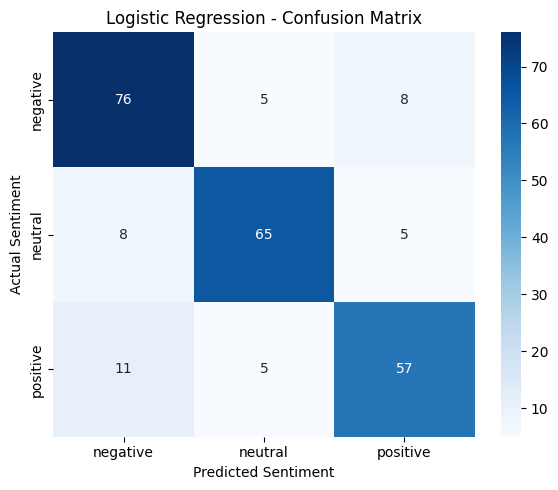

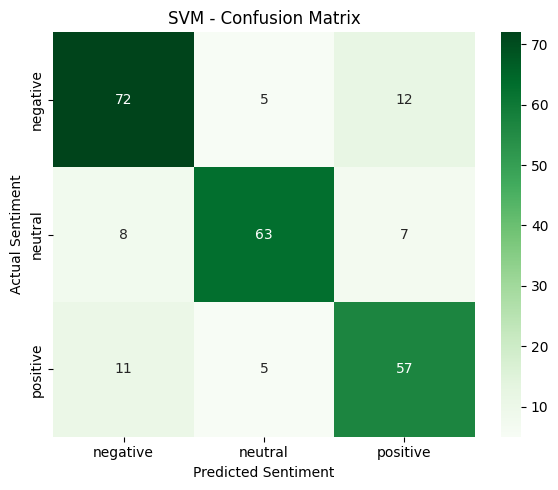

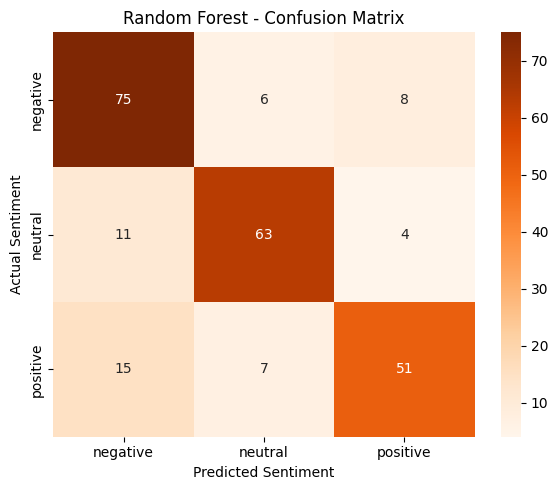

In [80]:

# ============================================================
# STEP 6.4 — CONFUSION MATRICES
# ============================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Get class names
classes = sorted(y_test.unique())

# ------------------------------------------------------------
# LOGISTIC REGRESSION
# ------------------------------------------------------------
cm_lr = confusion_matrix(
    y_test, y_pred_lr, labels=classes
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_lr,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# SVM
# ------------------------------------------------------------
cm_svm = confusion_matrix(
    y_test, y_pred_svm, labels=classes
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_svm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("SVM - Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# RANDOM FOREST
# Make sure y_pred_rf is already created
# ------------------------------------------------------------
cm_rf = confusion_matrix(
    y_test, y_pred_rf, labels=classes
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Oranges",
    xticklabels=classes,
    yticklabels=classes
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.tight_layout()
plt.show()

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

voting_accuracy = accuracy_score(y_test, y_pred_voting)

voting_precision = precision_score(
    y_test, y_pred_voting,
    average="weighted", zero_division=0
)

voting_recall = recall_score(
    y_test, y_pred_voting,
    average="weighted", zero_division=0
)

voting_f1 = f1_score(
    y_test, y_pred_voting,
    average="weighted", zero_division=0
)

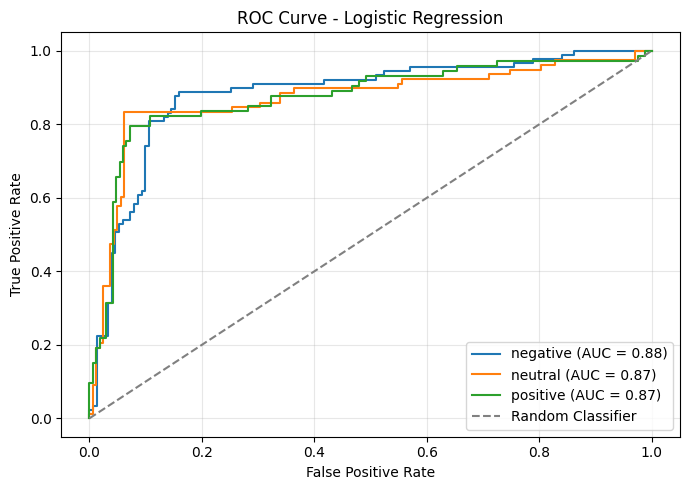

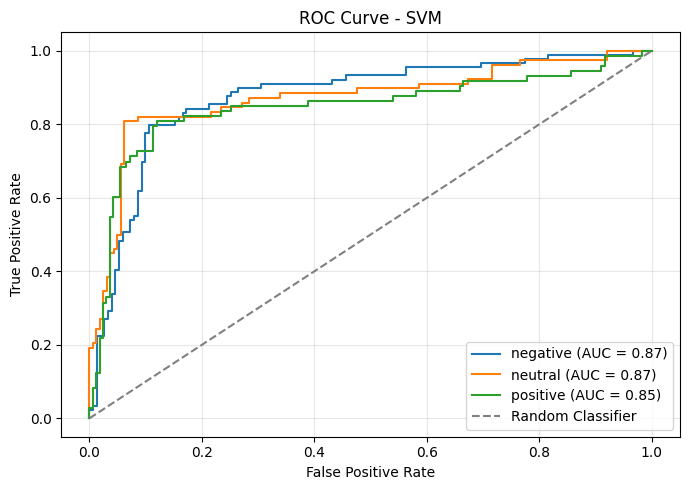

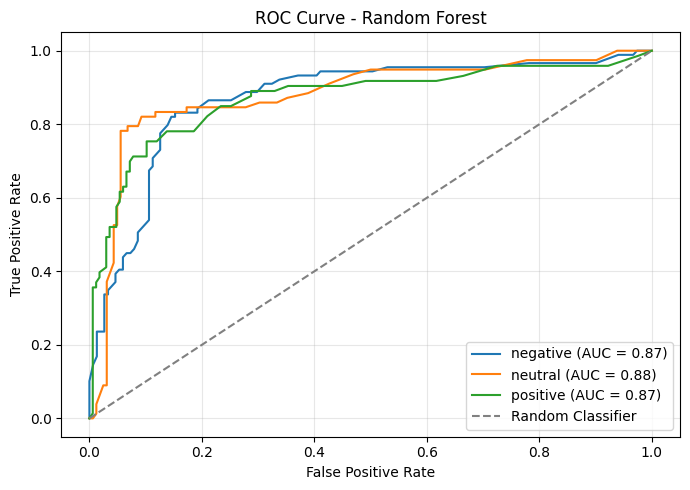

In [66]:

# ============================================================
# STEP 6.5 — ROC CURVE
# Logistic Regression, SVM, Random Forest
# ============================================================

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np

# Get class names
classes = sorted(y_test.unique())
n_classes = len(classes)

# Convert actual labels to binary format
y_test_binary = label_binarize(
    y_test,
    classes=classes
)

# Handle binary and multiclass classification consistently
if n_classes == 2 and y_test_binary.shape[1] == 1:
    y_test_binary = np.column_stack(
        [1 - y_test_binary[:, 0], y_test_binary[:, 0]]
    )

# ============================================================
# GET MODEL SCORES
# ============================================================

# Logistic Regression
lr_scores = logistic_model.predict_proba(X_test_tfidf)

# SVM
# Works with SVC when probability=True, or with
# decision_function for multiclass ROC scores.
svm_scores = svm_model.decision_function(X_test_tfidf)

# Random Forest
rf_scores = random_forest_model.predict_proba(X_test_tfidf)


# ============================================================
# HELPER FUNCTION TO PLOT ROC CURVE
# ============================================================

def plot_multiclass_roc(y_binary, scores, classes, model_name):

    # Convert binary-class decision scores to 2-column format
    if len(classes) == 2 and scores.ndim == 1:
        scores = np.column_stack([-scores, scores])

    plt.figure(figsize=(7, 5))

    for i, cls in enumerate(classes):

        fpr, tpr, _ = roc_curve(
            y_binary[:, i],
            scores[:, i]
        )

        roc_auc = auc(fpr, tpr)

        plt.plot(
            fpr,
            tpr,
            label=f"{cls} (AUC = {roc_auc:.2f})"
        )

    plt.plot(
        [0, 1], [0, 1],
        linestyle="--",
        color="gray",
        label="Random Classifier"
    )

    plt.title(f"ROC Curve - {model_name}")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


# ============================================================
# LOGISTIC REGRESSION ROC
# ============================================================

plot_multiclass_roc(
    y_test_binary,
    lr_scores,
    classes,
    "Logistic Regression"
)


# ============================================================
# SVM ROC
# ============================================================

plot_multiclass_roc(
    y_test_binary,
    svm_scores,
    classes,
    "SVM"
)


# ============================================================
# RANDOM FOREST ROC
# ============================================================

plot_multiclass_roc(
    y_test_binary,
    rf_scores,
    classes,
    "Random Forest"
)

In [67]:

# ============================================================
# STEP 7 — FINAL MODEL COMPARISON
# ============================================================

from sklearn.metrics import classification_report
import pandas as pd

# ============================================================
# LOGISTIC REGRESSION REPORT
# ============================================================

print("=" * 60)
print("LOGISTIC REGRESSION - CLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_test, y_pred_lr, zero_division=0
))


# ============================================================
# SVM REPORT
# ============================================================

print("=" * 60)
print("SVM - CLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_test, y_pred_svm, zero_division=0
))


# ============================================================
# RANDOM FOREST REPORT
# ============================================================

print("=" * 60)
print("RANDOM FOREST - CLASSIFICATION REPORT")
print("=" * 60)

print(classification_report(
    y_test, y_pred_rf, zero_division=0
))


# ============================================================
# FINAL COMPARISON TABLE
# ============================================================

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "SVM",
        "Random Forest"
    ],
    "Accuracy": [
        lr_accuracy * 100,
        svm_accuracy * 100,
        rf_accuracy * 100
    ],
    "Precision": [
        lr_precision * 100,
        svm_precision * 100,
        rf_precision * 100
    ],
    "Recall": [
        lr_recall * 100,
        svm_recall * 100,
        rf_recall * 100
    ],
    "F1-Score": [
        lr_f1 * 100,
        svm_f1 * 100,
        rf_f1 * 100
    ]
})

comparison = comparison.round(2)

print("\n" + "=" * 60)
print("FINAL MODEL COMPARISON")
print("=" * 60)

display(comparison)


# ============================================================
# BEST MODEL BASED ON ACCURACY
# ============================================================

accuracies = {
    "Logistic Regression": lr_accuracy,
    "SVM": svm_accuracy,
    "Random Forest": rf_accuracy
}

best_model = max(accuracies, key=accuracies.get)
best_accuracy = accuracies[best_model]

print("\n" + "=" * 60)
print("BEST MODEL")
print("=" * 60)
print("Best Model:", best_model)
print("Accuracy:", round(best_accuracy * 100, 2), "%")

LOGISTIC REGRESSION - CLASSIFICATION REPORT
              precision    recall  f1-score   support

    negative       0.80      0.85      0.83        89
     neutral       0.87      0.83      0.85        78
    positive       0.81      0.78      0.80        73

    accuracy                           0.82       240
   macro avg       0.83      0.82      0.82       240
weighted avg       0.83      0.82      0.82       240

SVM - CLASSIFICATION REPORT
              precision    recall  f1-score   support

    negative       0.79      0.81      0.80        89
     neutral       0.86      0.81      0.83        78
    positive       0.75      0.78      0.77        73

    accuracy                           0.80       240
   macro avg       0.80      0.80      0.80       240
weighted avg       0.80      0.80      0.80       240

RANDOM FOREST - CLASSIFICATION REPORT
              precision    recall  f1-score   support

    negative       0.74      0.84      0.79        89
     neutral       

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,82.50,82.6,82.50,82.50
1,SVM,80.00,80.2,80.00,80.06
2,Random Forest,78.75,79.1,78.75,78.68



BEST MODEL
Best Model: Logistic Regression
Accuracy: 82.5 %


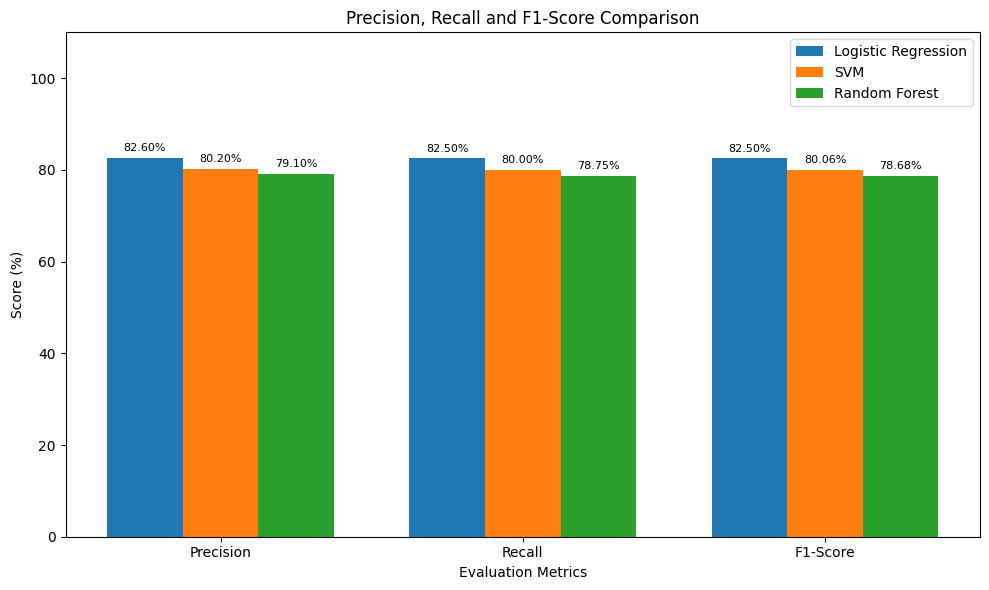

In [81]:

# ============================================================
# STEP 7.1 — PRECISION, RECALL AND F1-SCORE COMPARISON
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

# Logistic Regression metrics
lr_precision = precision_score(
    y_test, y_pred_lr, average="weighted", zero_division=0
)
lr_recall = recall_score(
    y_test, y_pred_lr, average="weighted", zero_division=0
)
lr_f1 = f1_score(
    y_test, y_pred_lr, average="weighted", zero_division=0
)

# SVM metrics
svm_precision = precision_score(
    y_test, y_pred_svm, average="weighted", zero_division=0
)
svm_recall = recall_score(
    y_test, y_pred_svm, average="weighted", zero_division=0
)
svm_f1 = f1_score(
    y_test, y_pred_svm, average="weighted", zero_division=0
)

# Random Forest metrics
rf_precision = precision_score(
    y_test, y_pred_rf, average="weighted", zero_division=0
)
rf_recall = recall_score(
    y_test, y_pred_rf, average="weighted", zero_division=0
)
rf_f1 = f1_score(
    y_test, y_pred_rf, average="weighted", zero_division=0
)

# Prepare chart data
metrics = ["Precision", "Recall", "F1-Score"]

logistic_scores = [
    lr_precision * 100,
    lr_recall * 100,
    lr_f1 * 100
]

svm_scores = [
    svm_precision * 100,
    svm_recall * 100,
    svm_f1 * 100
]

rf_scores_metrics = [
    rf_precision * 100,
    rf_recall * 100,
    rf_f1 * 100
]

# Plot grouped bar chart
x = np.arange(len(metrics))
width = 0.25

plt.figure(figsize=(10, 6))

bars1 = plt.bar(
    x - width, logistic_scores, width,
    label="Logistic Regression"
)

bars2 = plt.bar(
    x, svm_scores, width,
    label="SVM"
)

bars3 = plt.bar(
    x + width, rf_scores_metrics, width,
    label="Random Forest"
)

plt.title("Precision, Recall and F1-Score Comparison")
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score (%)")
plt.xticks(x, metrics)
plt.ylim(0, 110)

# Add values above bars
for bars in [bars1, bars2, bars3]:
    for bar in bars:
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 1,
            f"{bar.get_height():.2f}%",
            ha="center",
            va="bottom",
            fontsize=8
        )

plt.legend()
plt.tight_layout()
plt.show()

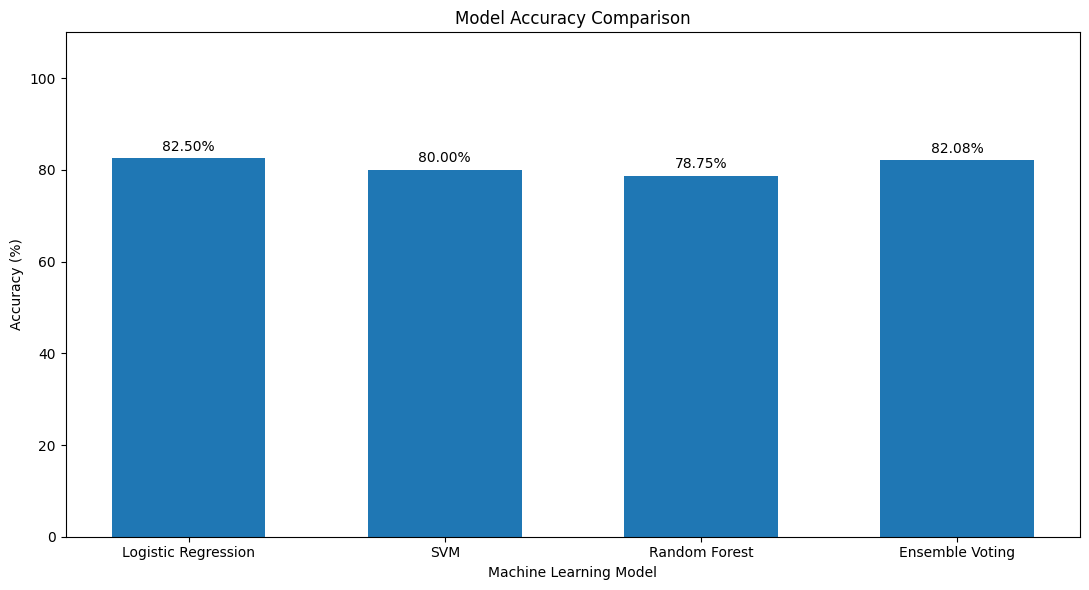

In [82]:

# ============================================================
# STEP 8 — MODEL COMPARISON VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

# Model names
models = [
    "Logistic Regression",
    "SVM",
    "Random Forest",
    "Ensemble Voting"
]

# Model accuracies
accuracies = [
    lr_accuracy * 100,
    svm_accuracy * 100,
    rf_accuracy * 100,
    voting_accuracy * 100
]

plt.figure(figsize=(11, 6))

bars = plt.bar(models, accuracies, width=0.6)

plt.title("Model Accuracy Comparison")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy (%)")

plt.ylim(0, 110)

# Display accuracy values above bars
for bar, value in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

In [83]:

# ============================================================
# STEP 9 — TEST NEW STUDENT COMMENTS
# ============================================================

new_comments = [
    "The faculty are very supportive and explain difficult topics clearly.",
    "The hostel maintenance is poor and complaints take too long to solve.",
    "The college conducts seminars and workshops every semester.",
    "The library is comfortable but there are not enough seats during exams.",
    "The campus facilities are excellent and students have many opportunities."
]

# Convert comments using the SAME trained TF-IDF vectorizer
new_comments_tfidf = tfidf.transform(new_comments)

# Predict sentiment using all three models
lr_predictions = logistic_model.predict(new_comments_tfidf)
svm_predictions = svm_model.predict(new_comments_tfidf)
rf_predictions = random_forest_model.predict(new_comments_tfidf)

# Display predictions
print("=" * 75)
print("NEW STUDENT COMMENTS — SENTIMENT PREDICTIONS")
print("=" * 75)

for i, comment in enumerate(new_comments):

    print(f"\nComment: {comment}")
    print("-" * 75)
    print("Logistic Regression :", lr_predictions[i])
    print("SVM                  :", svm_predictions[i])
    print("Random Forest        :", rf_predictions[i])

print("\nPrediction completed successfully!")

NEW STUDENT COMMENTS — SENTIMENT PREDICTIONS

Comment: The faculty are very supportive and explain difficult topics clearly.
---------------------------------------------------------------------------
Logistic Regression : negative
SVM                  : negative
Random Forest        : negative

Comment: The hostel maintenance is poor and complaints take too long to solve.
---------------------------------------------------------------------------
Logistic Regression : negative
SVM                  : negative
Random Forest        : negative

Comment: The college conducts seminars and workshops every semester.
---------------------------------------------------------------------------
Logistic Regression : neutral
SVM                  : neutral
Random Forest        : positive

Comment: The library is comfortable but there are not enough seats during exams.
---------------------------------------------------------------------------
Logistic Regression : negative
SVM                  : ne

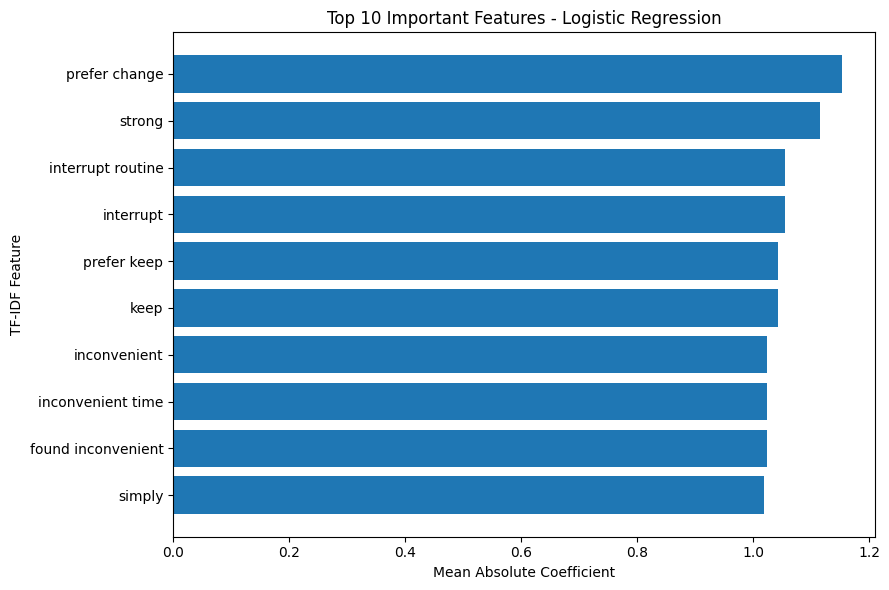

In [71]:

# ============================================================
# STEP 10.1 — TOP 10 FEATURE IMPORTANCE GRAPH
# LOGISTIC REGRESSION
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# Get TF-IDF feature names
feature_names = tfidf.get_feature_names_out()

# Get Logistic Regression coefficients
coefficients = logistic_model.coef_

# For multiclass classification, calculate mean absolute
# coefficient across classes
feature_importance = abs(coefficients).mean(axis=0)

# Create importance DataFrame
importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importance
})

# Select Top 10 features
top_10 = importance.nlargest(
    10, "Importance"
).sort_values(
    by="Importance",
    ascending=True
)

# Plot graph
plt.figure(figsize=(9, 6))

plt.barh(
    top_10["Feature"],
    top_10["Importance"]
)

plt.title("Top 10 Important Features - Logistic Regression")
plt.xlabel("Mean Absolute Coefficient")
plt.ylabel("TF-IDF Feature")

plt.tight_layout()
plt.show()

In [72]:
# ============================================================
# STEP 10 — FEATURE IMPORTANCE AND FINAL RESULTS
# ============================================================

import numpy as np
import pandas as pd

from sklearn.metrics import roc_auc_score


# ============================================================
# 1. GET FEATURE NAMES
# ============================================================

feature_names = tfidf.get_feature_names_out()


# ============================================================
# 2. CALCULATE FEATURE IMPORTANCE
# ============================================================
# Logistic Regression has one coefficient for each class.
# We use the average absolute coefficient as overall importance.

coefficients = logistic_model.coef_

importance_values = np.mean(
    np.abs(coefficients),
    axis=0
)


importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)


# ============================================================
# 3. TOP 10 FEATURES
# ============================================================

top_10 = importance.head(10)


print("=" * 70)
print("TOP 10 IMPORTANT FEATURES")
print("=" * 70)

for i, row in top_10.iterrows():
    print(
        f"{i+1}. {row['Feature']:<25} "
        f"{row['Importance']:.4f}"
    )


# ============================================================
# 4. AUC SCORE
# ============================================================

# Logistic Regression probability scores
y_prob_lr = logistic_model.predict_proba(X_test_tfidf)

auc_score = roc_auc_score(
    y_test,
    y_prob_lr,
    multi_class="ovr",
    average="weighted"
)


# ============================================================
# 5. FINAL RESULTS
# ============================================================

print("\n" + "=" * 70)
print("FINAL RESULTS")
print("=" * 70)

print("Algorithm Used  : Logistic Regression")
print("Accuracy Score  :", round(lr_accuracy * 100, 2), "%")
print("Precision Score :", round(lr_precision, 3))
print("Recall Score    :", round(lr_recall, 3))
print("F1 Score        :", round(lr_f1, 3))
print("AUC Score       :", round(auc_score, 3))

print("\nTop 10 Important Features")
print("-" * 70)

for i, row in top_10.iterrows():
    print(
        f"{i+1}. {row['Feature']:<25} "
        f"{row['Importance']:.4f}"
    )

print("-" * 70)


# ============================================================
# 6. CONCLUSION
# ============================================================

print("\n" + "=" * 70)
print("CONCLUSION")
print("=" * 70)

print("\nLogistic Regression successfully classified student comments")
print("into positive, negative, and neutral sentiment categories.")

print(
    "\nThe model achieved an accuracy of",
    round(lr_accuracy * 100, 2),
    "%"
)

print("The model demonstrated good predictive performance.")

print("\nImportant features influencing sentiment classification include:")

for i, row in top_10.head(5).iterrows():
    print("•", row["Feature"])

print("\nStudent Sentiment Analysis Completed Successfully.")

TOP 10 IMPORTANT FEATURES
1. prefer change             1.1534
2. strong                    1.1154
3. interrupt                 1.0551
4. interrupt routine         1.0551
5. keep                      1.0434
6. prefer keep               1.0434
7. inconvenient              1.0237
8. found inconvenient        1.0237
9. inconvenient time         1.0237
10. simply                    1.0197

FINAL RESULTS
Algorithm Used  : Logistic Regression
Accuracy Score  : 82.5 %
Precision Score : 0.826
Recall Score    : 0.825
F1 Score        : 0.825
AUC Score       : 0.876

Top 10 Important Features
----------------------------------------------------------------------
1. prefer change             1.1534
2. strong                    1.1154
3. interrupt                 1.0551
4. interrupt routine         1.0551
5. keep                      1.0434
6. prefer keep               1.0434
7. inconvenient              1.0237
8. found inconvenient        1.0237
9. inconvenient time         1.0237
10. simply       